In [9]:
import pandas as pd
from data_loading import data_loading,files
df = data_loading(files['final_df'])

In [49]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.base import BaseEstimator, ClassifierMixin
import joblib

In [8]:
df.shape

(513801, 52)

In [11]:
df.columns

Index(['collision_index', 'collision_severity', 'date', 'day_of_week', 'time',
       'latitude', 'longitude', 'urban_or_rural_area', 'speed_limit',
       'road_type', 'light_conditions', 'weather_conditions',
       'road_surface_conditions', 'special_conditions_at_site',
       'carriageway_hazards', 'junction_detail', 'junction_control',
       'trunk_road_flag', 'number_of_vehicles', 'number_of_casualties',
       'did_police_officer_attend_scene_of_accident',
       'collision_severity_label', 'day_of_week_label',
       'urban_or_rural_area_label', 'road_type_label',
       'light_conditions_label', 'weather_conditions_label',
       'road_surface_conditions_label', 'special_conditions_at_site_label',
       'carriageway_hazards_label', 'junction_detail_label',
       'junction_control_label', 'trunk_road_flag_label',
       'did_police_officer_attend_scene_of_accident_label', 'min_driver_age',
       'max_driver_age', 'max_vehicle_age', 'max_engine_cc',
       'male_driver_shar

In [13]:
y = df['collision_severity'].isin([1, 2]).astype(int)

num_cols = [
    'speed_limit', 'number_of_vehicles', 'min_driver_age', 'max_driver_age', 'max_engine_cc', 'male_driver_share', 'avg_casualty_imd'
]

bin_cols = [
    'has_cycle', 'has_motorcycle', 'has_goods_vehicle', 'has_bus', 'has_vulnerable_vehicle', 'has_overtaking', 'has_turning', 'has_vulnerable_casualty', 'has_escooter_casualty', 'has_pedestrian_movement'
]

cat_cols = [
    'urban_or_rural_area', 'road_type', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'junction_detail', 'junction_control', 'day_of_week'
]

df[cat_cols] = df[cat_cols].astype('category')

In [15]:
X = df[num_cols + bin_cols + cat_cols]

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train", X_train.shape)
print("X_test", X_test.shape)
print("\ny_train class counts:")
print(y_train.value_counts())
print("\ny_test class counts:")
print(y_test.value_counts())

X_train (411040, 25)
X_test (102761, 25)

y_train class counts:
collision_severity
0    311547
1     99493
Name: count, dtype: int64

y_test class counts:
collision_severity
0    77888
1    24873
Name: count, dtype: int64


In [23]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('bin', 'passthrough', bin_cols),
    ]
)


In [25]:
pipe = Pipeline(steps=[
    ('pre', preprocessor),
    ('rf', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

pipe.fit(X_train, y_train)

print("Train accuracy:", pipe.score(X_train, y_train))
print("Test accuracy :", pipe.score(X_test, y_test))



Train accuracy: 0.998024523160763
Test accuracy : 0.7609404346006754


In [28]:
y_pred = pipe.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Slight (0)', 'KSI (1)']))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix")
print(cm)

              precision    recall  f1-score   support

  Slight (0)       0.78      0.96      0.86     77888
     KSI (1)       0.52      0.15      0.23     24873

    accuracy                           0.76    102761
   macro avg       0.65      0.55      0.54    102761
weighted avg       0.72      0.76      0.71    102761

Confusion matrix
[[74561  3327]
 [21239  3634]]


In [30]:
y_baseline = np.zeros(len(y_test))
print("Baseline accuracy (always 'slight'): ", (y_baseline == y_test).mean())
print("Model accuracy: ", pipe.score(X_test, y_test))

Baseline accuracy (always 'slight'):  0.7579529198820564
Model accuracy:  0.7609404346006754


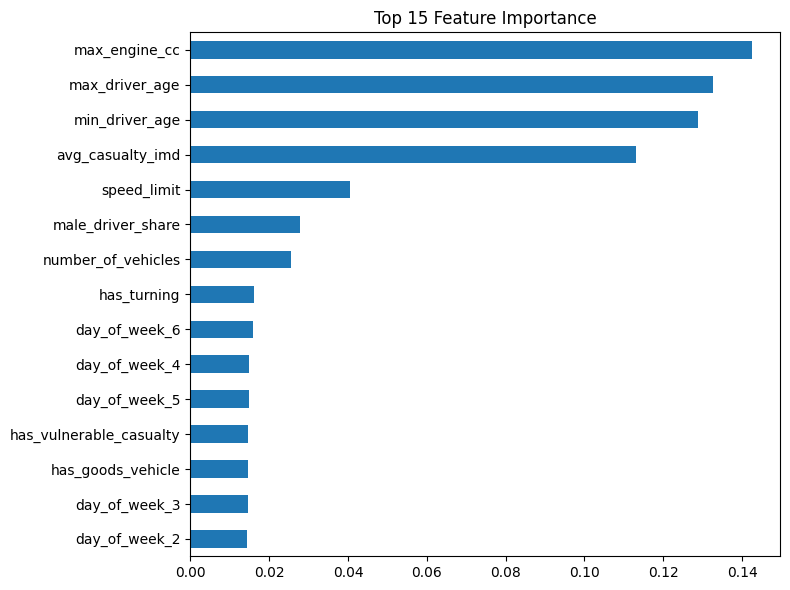

In [37]:
ohe = pipe.named_steps['pre'].named_transformers_['cat']
feature_names = num_cols + list(ohe.get_feature_names_out(cat_cols)) + bin_cols

imp = (pd.Series(pipe.named_steps['rf'].feature_importances_, index=feature_names).sort_values(ascending=False).head(15))

imp.sort_values().plot(kind='barh', figsize=(8, 6), title="Top 15 Feature Importance")
plt.tight_layout()
plt.show()

In [38]:
# New pipe

pipe2 = Pipeline(steps=[
    ('pre', preprocessor),
    ('rf', RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

pipe2.fit(X_train, y_train)
print("Train accuracy:", pipe2.score(X_train, y_train))
print("Test accuracy :", pipe2.score(X_test, y_test))

Train accuracy: 0.6906067536006228
Test accuracy : 0.6516090734811845


              precision    recall  f1-score   support

  Slight (0)       0.84      0.66      0.74     77888
     KSI (1)       0.37      0.62      0.46     24873

    accuracy                           0.65    102761
   macro avg       0.61      0.64      0.60    102761
weighted avg       0.73      0.65      0.67    102761

Confusion matrix
[[51598 26290]
 [ 9511 15362]]
Baseline accuracy (always 'slight'):  0.7579529198820564
Model accuracy:  0.6516090734811845


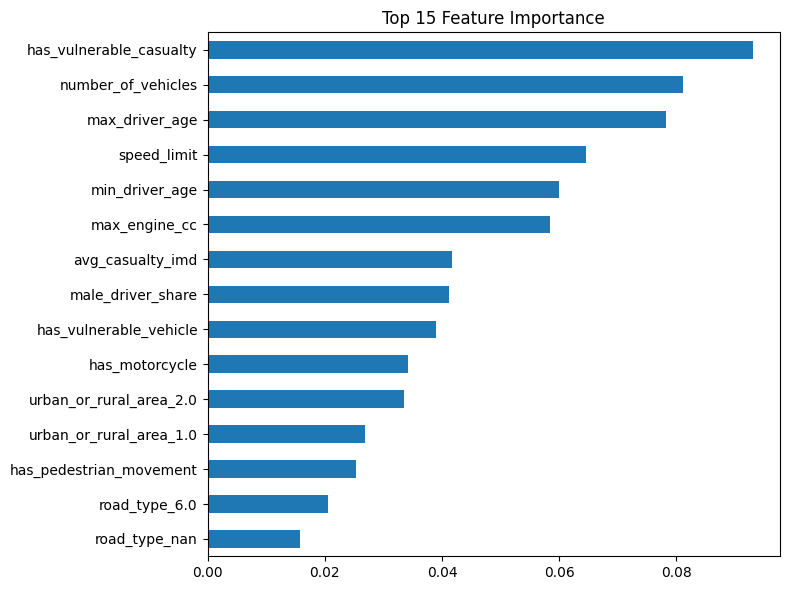

In [40]:
y_pred = pipe2.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Slight (0)', 'KSI (1)']))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix")
print(cm)

# ----
y_baseline = np.zeros(len(y_test))
print("Baseline accuracy (always 'slight'): ", (y_baseline == y_test).mean())
print("Model accuracy: ", pipe2.score(X_test, y_test))
# ----
ohe = pipe2.named_steps['pre'].named_transformers_['cat']
feature_names = num_cols + list(ohe.get_feature_names_out(cat_cols)) + bin_cols

imp = (pd.Series(pipe2.named_steps['rf'].feature_importances_, index=feature_names).sort_values(ascending=False).head(15))

imp.sort_values().plot(kind='barh', figsize=(8, 6), title="Top 15 Feature Importance")
plt.tight_layout()
plt.show()

In [45]:
# threshold sweep

y_prob = pipe2.predict_proba(X_test)[:, 1]

best = (0, 0, 0, 0)
print("thr | precision | recall | f1")
print("-"  * 30)

for t in np.arange(0.20, 0.85, 0.05):
  y_pred_t = (y_prob  >= t).astype(int)
  p, r, f1, _ = precision_recall_fscore_support(
      y_test, y_pred_t, average='binary', pos_label=1
  )
  print(f"{t:.2f} | {p:.3f} | {r:.3f} | {f1:.3f}")
  if f1 > best[3]:
    best = [t, p, r, f1]
print("\nBest threshold:", round(best[0], 2),
      "-> P:", round(best[1], 3), "F1:", round(best[3], 3))

thr | precision | recall | f1
------------------------------
0.20 | 0.251 | 0.995 | 0.400
0.25 | 0.258 | 0.982 | 0.409
0.30 | 0.275 | 0.946 | 0.426
0.35 | 0.294 | 0.892 | 0.443
0.40 | 0.316 | 0.822 | 0.457
0.45 | 0.338 | 0.740 | 0.464
0.50 | 0.369 | 0.618 | 0.462
0.55 | 0.408 | 0.474 | 0.438
0.60 | 0.466 | 0.316 | 0.377
0.65 | 0.536 | 0.185 | 0.276
0.70 | 0.601 | 0.118 | 0.197
0.75 | 0.653 | 0.076 | 0.136
0.80 | 0.670 | 0.047 | 0.088

Best threshold: 0.45 -> P: 0.338 F1: 0.464


In [48]:
# Final model: threshold 0.45

def predict_final(X, threshold=0.45):
  proba = pipe2.predict_proba(X)[:, 1]
  return (proba >= threshold).astype(int)

y_pred_final = predict_final(X_test,threshold=0.45)


print("=" * 50)
print("FINAL MODEL — threshold = 0.45")
print("=" * 50)
print(classification_report(y_test, y_pred_final, target_names=['slight (0)', 'KSI (1)']))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_final))


FINAL MODEL — threshold = 0.45
              precision    recall  f1-score   support

  slight (0)       0.87      0.54      0.66     77888
     KSI (1)       0.34      0.74      0.46     24873

    accuracy                           0.59    102761
   macro avg       0.60      0.64      0.56    102761
weighted avg       0.74      0.59      0.61    102761

Confusion matrix:
[[41824 36064]
 [ 6471 18402]]


In [53]:
# Saving the model
joblib.dump({
    'model': pipe2,
    'threshold': 0.45
}, 'model_bundle.pkl')
print("Saved: model_bundle.pkl")

Saved: model_bundle.pkl


In [54]:
# Verifying:
bundle = joblib.load('model_bundle.pkl')
y_check = (bundle['model'].predict_proba(X_test)[:, 1]>=bundle['threshold']).astype(int)
print("Load verify: same predictions?", (y_check == y_pred_final).all())

!ls -lh model_bundle.pkl

Load verify: same predictions? True
-rw-r--r-- 1 root root 90M Nov 11 07:28 model_bundle.pkl
